# 01 — Pipeline Base: M4 Mensal + Rolling Origin + Baseline de Persistência

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE1 + OE2 — Implementação inicial e validação do protocolo experimental

---
### O que este notebook faz
1. Carrega os CSVs do M4 Mensal (train + test)
2. Inspeciona a distribuição de comprimentos das séries
3. Implementa o protocolo **rolling origin** com janela expansiva
4. Executa o **baseline de persistência** (último valor observado)
5. Calcula MAPE, MAE e R² por janela e agrega por série
6. Salva resultados em CSV para rastreabilidade

> **Nota**: rodamos com um **piloto de 200 séries** para validar o pipeline. Depois basta remover o filtro para escalar.

## 0. Instalação de dependências
Execute esta célula apenas uma vez.

In [ ]:
# Com o venv ativo na raiz do projeto, prefira no terminal:
#   pip install -r requirements.txt
# Se precisar instalar daqui (cwd = pasta do notebook), use:
# !pip install -r ../requirements.txt

## 1. Imports e configurações globais

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
import time

warnings.filterwarnings('ignore')

# ── Caminhos (funciona com cwd em autopred/ ou notebooks/) ───────────────────
import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'paths.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.paths import DATA_DIR, PROJECT_ROOT, RESULT_DIR

RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ── Semente para reprodutibilidade ───────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Parâmetros do protocolo (seção 4.2 da dissertação) ───────────────────────
H          = 18    # horizonte M4 mensal (padrão da competição)
MIN_TRAIN  = 24    # mínimo de dois ciclos sazonais
N_ORIGINS  = 3     # origens por série
PILOT_N    = 200   # séries no piloto — None para rodar todas

print('Configuração carregada OK')
print(f'  Horizonte H      = {H} meses')
print(f'  Mínimo treino    = {MIN_TRAIN} obs')
print(f'  Origens rolling  = {N_ORIGINS}')
print(f'  Piloto           = {PILOT_N if PILOT_N else "TODAS AS SERIES"}')

Configuração carregada OK
  Horizonte H      = 18 meses
  Mínimo treino    = 24 obs
  Origens rolling  = 3
  Piloto           = 200


## 2. Carregamento dos dados

In [2]:
def load_m4_monthly(data_dir: Path):
    """
    Lê Monthly-train.csv e Monthly-test.csv do M4.
    Converte do formato wide (uma coluna por passo) para long
    (colunas: unique_id | step | y).
    """
    train_raw = pd.read_csv(data_dir / 'Monthly-train.csv')
    test_raw  = pd.read_csv(data_dir / 'Monthly-test.csv')

    def wide_to_long(df):
        id_col     = df.columns[0]     # primeira coluna: 'V1' ou nome do ID
        value_cols = df.columns[1:]
        melted = df.melt(
            id_vars    = id_col,
            value_vars = value_cols,
            var_name   = 'step_raw',
            value_name = 'y'
        )
        melted = melted.rename(columns={id_col: 'unique_id'})
        melted['step'] = melted['step_raw'].str.extract(r'(\d+)').astype(int)
        melted = melted.drop(columns='step_raw')
        melted = melted.dropna(subset=['y'])
        melted = melted.sort_values(['unique_id','step']).reset_index(drop=True)
        return melted

    return wide_to_long(train_raw), wide_to_long(test_raw)


train_df, test_df = load_m4_monthly(DATA_DIR)

print('=== TRAIN ===')
print(f'  Linhas        : {len(train_df):,}')
print(f'  Séries únicas : {train_df["unique_id"].nunique():,}')
print(train_df.head(6).to_string(index=False))
print('\n=== TEST ===')
print(f'  Linhas        : {len(test_df):,}')
print(f'  Séries únicas : {test_df["unique_id"].nunique():,}')
print(test_df.head(6).to_string(index=False))

=== TRAIN ===
  Linhas        : 10,382,411
  Séries únicas : 48,000
unique_id      y  step
       M1 8000.0     2
       M1 8350.0     3
       M1 8570.0     4
       M1 7700.0     5
       M1 7080.0     6
       M1 6520.0     7

=== TEST ===
  Linhas        : 864,000
  Séries únicas : 48,000
unique_id      y  step
       M1 8720.0     2
       M1 7790.0     3
       M1 4770.0     4
       M1 5060.0     5
       M1 4720.0     6
       M1 4450.0     7


## 3. Análise exploratória dos comprimentos

In [3]:
lengths = train_df.groupby('unique_id')['y'].count().rename('n_obs')
print('Distribuição de comprimentos:')
print(lengths.describe().round(1).to_string())
curtas = (lengths < 36).sum()
print(f'\nSéries com < 36 obs (insuficiência amostral): {curtas} ({100*curtas/len(lengths):.1f}%)')

Distribuição de comprimentos:
count    48000.0
mean       216.3
std        137.4
min         42.0
25%         82.0
50%        202.0
75%        306.0
max       2794.0

Séries com < 36 obs (insuficiência amostral): 0 (0.0%)


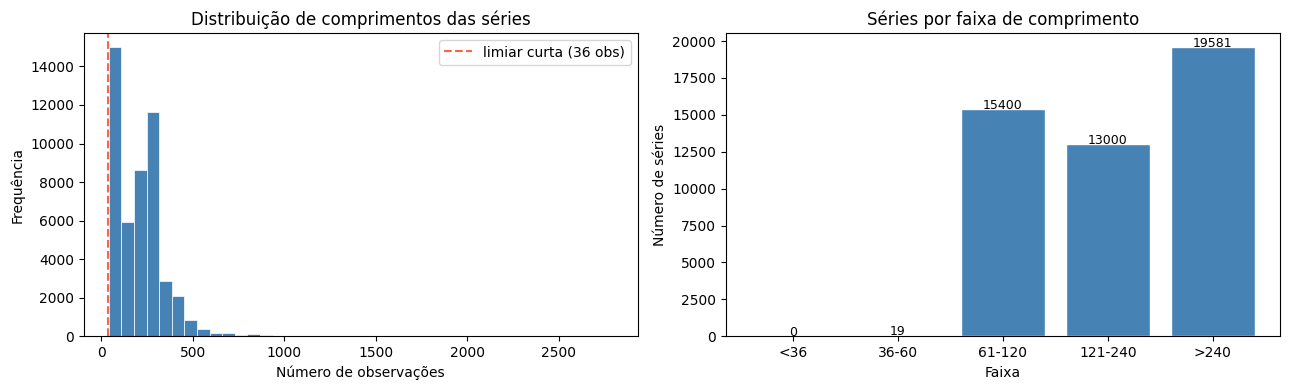

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(lengths, bins=40, color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].axvline(36, color='tomato', linestyle='--', linewidth=1.5, label='limiar curta (36 obs)')
axes[0].set_title('Distribuição de comprimentos das séries')
axes[0].set_xlabel('Número de observações')
axes[0].set_ylabel('Frequência')
axes[0].legend()

bins   = [0, 36, 60, 120, 240, lengths.max()+1]
labels = ['<36','36-60','61-120','121-240','>240']
faixa  = pd.cut(lengths, bins=bins, labels=labels, right=False)
counts = faixa.value_counts().reindex(labels)
axes[1].bar(counts.index, counts.values, color='steelblue', edgecolor='white')
axes[1].set_title('Séries por faixa de comprimento')
axes[1].set_xlabel('Faixa')
axes[1].set_ylabel('Número de séries')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 30, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_comprimentos_m4_mensal.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Seleção do piloto

In [ ]:
all_ids = train_df['unique_id'].unique()

if PILOT_N is not None:
    rng = np.random.default_rng(SEED)
    pilot_ids = rng.choice(all_ids, size=PILOT_N, replace=False)
    print(f'Piloto: {PILOT_N} séries (seed={SEED})')
else:
    pilot_ids = all_ids
    print(f'Todas as {len(all_ids)} séries')

train_pilot = train_df[train_df['unique_id'].isin(pilot_ids)].copy()
test_pilot  = test_df[test_df['unique_id'].isin(pilot_ids)].copy()
print(f'Train piloto : {len(train_pilot):,} linhas')
print(f'Test piloto  : {len(test_pilot):,} linhas')


Piloto: 200 séries (seed=42)
Train piloto : 44,224 linhas
Test piloto  : 3,600 linhas


## 5. Rolling Origin
Janela expansiva — ordem cronológica preservada, sem vazamento temporal (seção 4.2).

In [6]:
def make_rolling_windows(series, horizon, min_train, n_origins):
    """
    Gera janelas de rolling origin com expansão.
    Retorna lista de dicts {origin, train, test} ou [] se série curta demais.
    """
    n = len(series)
    if n < min_train + horizon:
        return []

    last_origin  = n - horizon
    first_origin = min_train

    if last_origin <= first_origin:
        return []

    if n_origins == 1:
        origins = [last_origin]
    else:
        origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
        origins = sorted(set(origins))

    windows = []
    for origin in origins:
        test_slice = series[origin : origin + horizon]
        if len(test_slice) == horizon:
            windows.append({
                'origin': origin,
                'train' : series[:origin],
                'test'  : test_slice
            })
    return windows


# Teste rápido
serie_teste = np.arange(1, 61, dtype=float)
janelas = make_rolling_windows(serie_teste, horizon=18, min_train=24, n_origins=3)
print(f'Série de 60 obs → {len(janelas)} janelas')
for j in janelas:
    print(f'  origin={j["origin"]:3d} | treino={len(j["train"])} | teste={len(j["test"])}')

Série de 60 obs → 3 janelas
  origin= 24 | treino=24 | teste=18
  origin= 33 | treino=33 | teste=18
  origin= 42 | treino=42 | teste=18


## 6. Baseline de Persistência
Repete o último valor observado para todos os H passos. Piso mínimo de comparação (seção 5.1).

In [7]:
def baseline_persistence(train, horizon):
    """Último valor observado repetido H vezes."""
    return np.full(horizon, train[-1])

print('Teste:', baseline_persistence(np.array([10,11,12,15.5]), horizon=4))

Teste: [15.5 15.5 15.5 15.5]


## 7. Métricas — MAPE, MAE, R² (seção 4.5)

In [8]:
def calc_mape(y_true, y_pred):
    """MAPE com proteção contra divisão por zero."""
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

# Verificação rápida
y_t = np.array([100, 110, 120, 130], dtype=float)
y_p = np.array([100, 100, 100, 100], dtype=float)
m   = calc_metrics(y_t, y_p)
print(f'MAPE={m["mape"]:.2f}%  MAE={m["mae"]:.2f}  R²={m["r2"]:.4f}')

MAPE=12.21%  MAE=15.00  R²=-1.8000


## 8. Pipeline completo

In [9]:
def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn):
    """
    Executa rolling origin para todas as séries e retorna DataFrame
    com uma linha por (série × janela).
    Campos: unique_id, model, origin, n_train, mape, mae, r2, exec_time_s, status
    """
    records = []
    for uid in train_df['unique_id'].unique():
        values  = train_df[train_df['unique_id'] == uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)

        if not windows:
            records.append({'unique_id': uid, 'model': model_name,
                            'origin': None, 'n_train': None,
                            'mape': None, 'mae': None, 'r2': None,
                            'exec_time_s': None, 'status': 'SKIP_SHORT'})
            continue

        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape': None, 'mae': None, 'r2': None}
                status  = f'ERROR: {e}'
            elapsed = time.perf_counter() - t0

            records.append({
                'unique_id'  : uid,
                'model'      : model_name,
                'origin'     : win['origin'],
                'n_train'    : len(win['train']),
                **metrics,
                'exec_time_s': elapsed,
                'status'     : status
            })

    return pd.DataFrame(records)

In [10]:
print(f'Executando baseline de persistência em {len(pilot_ids)} séries...')
t0 = time.time()

results = run_pipeline(
    train_df   = train_pilot,
    horizon    = H,
    min_train  = MIN_TRAIN,
    n_origins  = N_ORIGINS,
    model_name = 'persistence',
    predict_fn = baseline_persistence
)

print(f'Concluído em {time.time()-t0:.1f}s')
results.head(8)

Executando baseline de persistência em 200 séries...
Concluído em 0.6s


,unique_id,model,origin,n_train,mape,mae,r2,exec_time_s,status
0,M10314,persistence,24,24,19.329094,940.327778,-1.774943,0.000667,OK
1,M10314,persistence,83,83,27.011612,527.366667,-4.959199,0.000452,OK
2,M10314,persistence,143,143,12.753582,410.022222,-0.366884,0.000444,OK
3,M10979,persistence,24,24,7.306293,105.000000,-14.124555,0.000467,OK
4,M10979,persistence,156,156,8.881522,123.888889,-11.997346,0.000462,OK
5,M10979,persistence,288,288,4.727124,70.000000,-3.113596,0.000415,OK
6,M11327,persistence,24,24,2.535092,168.888889,-0.617358,0.000475,OK
7,M11327,persistence,156,156,1.098493,97.777778,-1.133895,0.000414,OK


## 9. Análise dos resultados

In [11]:
ok      = results[results['status'] == 'OK'].copy()
skipped = (results['status'] == 'SKIP_SHORT').sum()
errors  = results['status'].str.startswith('ERROR', na=False).sum()
n_tent  = results['origin'].notna().sum()
taxa    = 100 * len(ok) / n_tent if n_tent > 0 else 0

print('Status da execução:')
print(f'  OK           : {len(ok):,} janelas')
print(f'  Skip (curta) : {skipped}')
print(f'  Erros        : {errors}')
print(f'  Taxa sucesso : {taxa:.1f}%')

Status da execução:
  OK           : 600 janelas
  Skip (curta) : 0
  Erros        : 0
  Taxa sucesso : 100.0%


In [12]:
# Agrega por série — mediana entre janelas (robusto a outliers)
by_series = ok.groupby('unique_id')[['mape','mae','r2']].median().reset_index()

print('=== Desempenho geral — Baseline Persistência ===')
print(by_series[['mape','mae','r2']].describe().round(3).to_string())
print(f'\nMAPE mediano = {by_series["mape"].median():.2f}%')
print(f'MAE  mediano = {by_series["mae"].median():.4f}')
print(f'R²   mediano = {by_series["r2"].median():.4f}')

=== Desempenho geral — Baseline Persistência ===
          mape       mae       r2
count  200.000   200.000  200.000
mean    13.487   503.693   -1.888
std     16.443   750.580    2.232
min      1.098    17.144  -14.585
25%      3.962   114.139   -2.453
50%      8.699   274.167   -1.268
75%     17.215   543.536   -0.416
max    128.842  6152.222   -0.003

MAPE mediano = 8.70%
MAE  mediano = 274.1667
R²   mediano = -1.2684


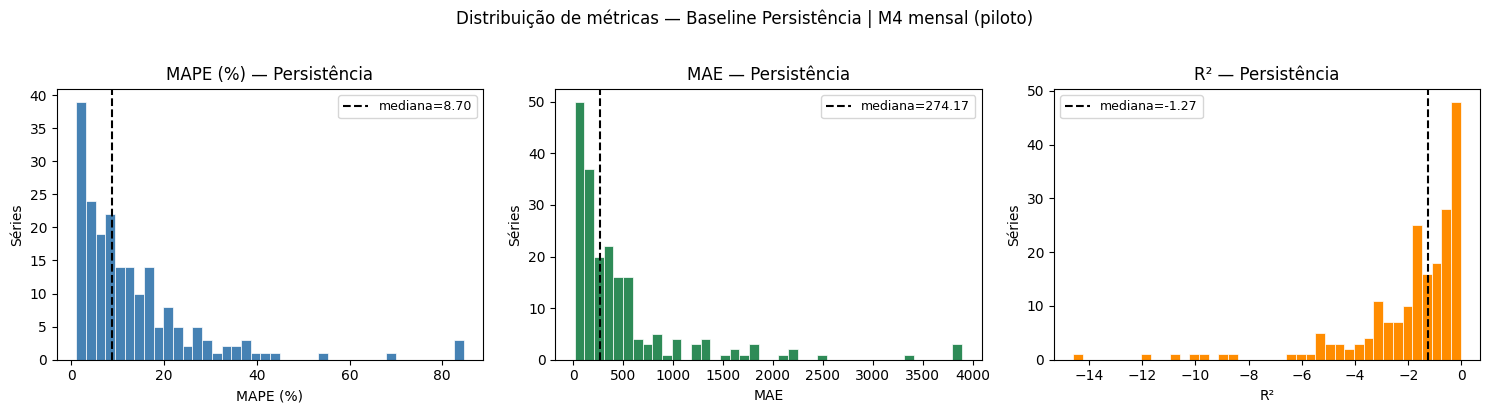

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, label, color) in zip(axes, [
    ('mape','MAPE (%)','steelblue'),
    ('mae', 'MAE',     'seagreen'),
    ('r2',  'R²',      'darkorange')
]):
    data = by_series[col].dropna()
    ax.hist(data.clip(upper=data.quantile(0.99)), bins=40,
            color=color, edgecolor='white', linewidth=0.5)
    ax.axvline(data.median(), color='black', linestyle='--', linewidth=1.5,
               label=f'mediana={data.median():.2f}')
    ax.set_title(f'{label} — Persistência')
    ax.set_xlabel(label)
    ax.set_ylabel('Séries')
    ax.legend(fontsize=9)

plt.suptitle('Distribuição de métricas — Baseline Persistência | M4 mensal (piloto)', y=1.02)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_metricas_persistencia.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Visualização de exemplo — uma série

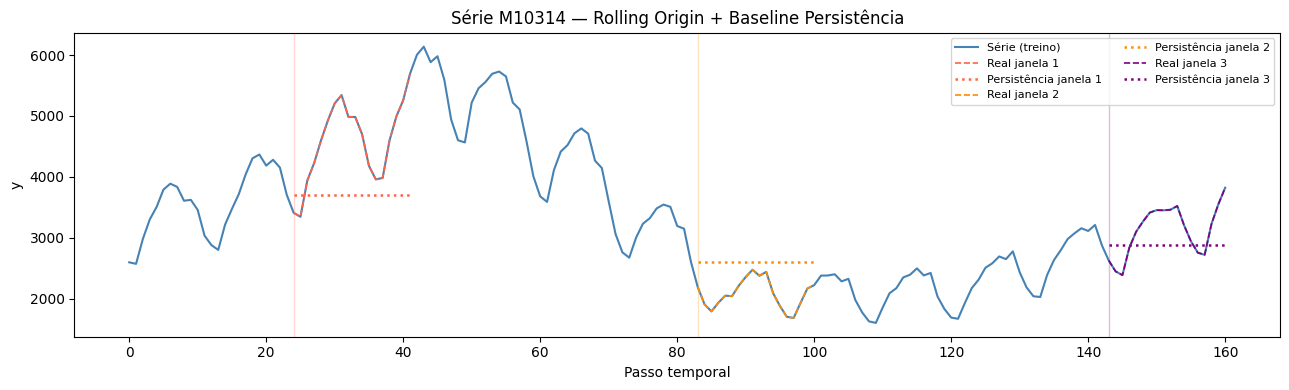

In [14]:
ex_uid  = ok['unique_id'].iloc[0]
ex_vals = train_pilot[train_pilot['unique_id'] == ex_uid]['y'].values.astype(float)
ex_wins = make_rolling_windows(ex_vals, H, MIN_TRAIN, N_ORIGINS)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(range(len(ex_vals)), ex_vals, color='steelblue',
        linewidth=1.5, label='Série (treino)')

colors = ['tomato','darkorange','purple']
for i, win in enumerate(ex_wins):
    origin = win['origin']
    pred   = baseline_persistence(win['train'], H)
    xr     = range(origin, origin + H)
    ax.plot(xr, win['test'], '--', color=colors[i], linewidth=1.2,
            label=f'Real janela {i+1}')
    ax.plot(xr, pred, ':',  color=colors[i], linewidth=1.8,
            label=f'Persistência janela {i+1}')
    ax.axvline(origin, color=colors[i], alpha=0.25, linewidth=1)

ax.set_title(f'Série {ex_uid} — Rolling Origin + Baseline Persistência')
ax.set_xlabel('Passo temporal')
ax.set_ylabel('y')
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(RESULT_DIR / f'fig_exemplo_{ex_uid}.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Salvando artefatos (seção 6.3 — rastreabilidade)

In [15]:
import json
from datetime import datetime

run_log = {
    'timestamp'    : datetime.now().isoformat(),
    'dataset'      : 'M4_Monthly',
    'pilot_n'      : PILOT_N,
    'seed'         : SEED,
    'horizon_H'    : H,
    'min_train'    : MIN_TRAIN,
    'n_origins'    : N_ORIGINS,
    'model'        : 'persistence',
    'n_ok'         : int(len(ok)),
    'n_skip_short' : int(skipped),
    'n_errors'     : int(errors),
    'taxa_sucesso' : round(taxa, 2),
    'mape_median'  : round(float(by_series['mape'].median()), 4),
    'mae_median'   : round(float(by_series['mae'].median()),  4),
    'r2_median'    : round(float(by_series['r2'].median()),   4),
}

with open(RESULT_DIR / 'run_log_persistence.json', 'w') as f:
    json.dump(run_log, f, indent=2)

results.to_csv(RESULT_DIR / 'results_persistence_by_window.csv', index=False)
by_series.to_csv(RESULT_DIR / 'results_persistence_by_series.csv', index=False)

print('Arquivos salvos em results/:')
print('  run_log_persistence.json')
print('  results_persistence_by_window.csv')
print('  results_persistence_by_series.csv')
print()
print(json.dumps(run_log, indent=2))

Arquivos salvos em results/:
  run_log_persistence.json
  results_persistence_by_window.csv
  results_persistence_by_series.csv

{
  "timestamp": "2026-05-11T15:17:42.262799",
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "min_train": 24,
  "n_origins": 3,
  "model": "persistence",
  "n_ok": 600,
  "n_skip_short": 0,
  "n_errors": 0,
  "taxa_sucesso": 100.0,
  "mape_median": 8.6992,
  "mae_median": 274.1667,
  "r2_median": -1.2684
}


## 12. Resumo e próximos passos

| Etapa | Status |
|---|---|
| Carregamento M4 mensal (wide → long) | ✓ |
| Análise exploratória de comprimentos | ✓ |
| Rolling origin (janela expansiva) | ✓ |
| Baseline de persistência | ✓ |
| Métricas: MAPE, MAE, R² | ✓ |
| Log de rastreabilidade | ✓ |

---

### Próximo notebook: `02_baselines_e_holt_winters.ipynb`
- Baseline de **média histórica**
- Baseline **sazonal ingênuo** (mesmo mês do ano anterior)
- Primeiro modelo real: **Holt-Winters**
- Comparação dos três lado a lado